In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
from pathlib import Path
import io
import json
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
DATA_DIR = Path("/content/bank_marketing_data")
OUTPUT_DIR = Path("/content/bank_marketing_eda_outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "bank-full.csv"

In [27]:
def download_and_load_bank_data():
    'Download the UCI archive and read bank-full.csv from its nested ZIP.'
    if CSV_PATH.exists():
        return pd.read_csv(CSV_PATH, sep=";")

    request = urllib.request.Request(
        DATA_URL,
        headers={"User-Agent": "Mozilla/5.0 (compatible; ColabCourseProject/1.0)"},
    )
    try:
        with urllib.request.urlopen(request, timeout=90) as response:
            archive_bytes = response.read()
    except Exception as exc:
        raise RuntimeError(
            "UCI download failed. Check the Colab internet connection and retry. "
            f"Dataset URL: {DATA_URL}"
        ) from exc

    csv_bytes = None
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as outer_zip:
        for member in outer_zip.namelist():
            if not member.lower().endswith(".zip"):
                continue
            try:
                with zipfile.ZipFile(io.BytesIO(outer_zip.read(member))) as nested_zip:
                    csv_members = [
                        name for name in nested_zip.namelist()
                        if name.lower().endswith("bank-full.csv")
                    ]
                    if csv_members:
                        csv_bytes = nested_zip.read(csv_members[0])
                        break
            except zipfile.BadZipFile:
                continue

    if csv_bytes is None:
        raise RuntimeError("bank-full.csv was not found in the downloaded UCI archive.")
    CSV_PATH.write_bytes(csv_bytes)
    data = pd.read_csv(io.BytesIO(csv_bytes), sep=";")
    expected = {
        "age", "job", "marital", "education", "default", "balance", "housing",
        "loan", "contact", "day", "month", "duration", "campaign", "pdays",
        "previous", "poutcome", "y",
    }
    if not expected.issubset(data.columns):
        raise ValueError(f"Unexpected columns in source dataset: {list(data.columns)}")
    return data


df = download_and_load_bank_data()
print(f"Loaded {len(df):,} records and {df.shape[1] - 1} input variables.")
display(df.head())


Loaded 45,211 records and 16 input variables.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [28]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_rows": df.isna().sum(),
    "unknown_category_rows": (df.astype(str) == "unknown").sum(),
}))

class_counts = df["y"].value_counts().reindex(["no", "yes"], fill_value=0)
class_rates = (class_counts / class_counts.sum()).rename("share")
display(pd.concat([class_counts.rename("rows"), class_rates], axis=1))


,dtype,missing_rows,unknown_category_rows
age,int64,0,0
job,object,0,288
marital,object,0,0
education,object,0,1857
default,object,0,0
balance,int64,0,0
housing,object,0,0
loan,object,0,0
contact,object,0,13020
day,int64,0,0


,rows,share
y,,
no,39922,0.883015
yes,5289,0.116985


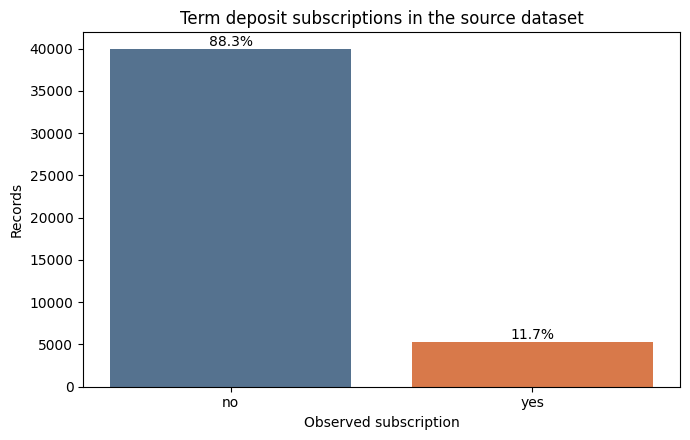

In [29]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(class_counts.index, class_counts.values, color=["#55728f", "#d8794a"])
ax.set_title("Term deposit subscriptions in the source dataset")
ax.set_ylabel("Records")
ax.set_xlabel("Observed subscription")
for bar, share in zip(bars, class_rates.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{share:.1%}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()


,mean,count
job,,
blue-collar,0.072750,9732
entrepreneur,0.082717,1487
housemaid,0.087903,1240
services,0.088830,4154
technician,0.110570,7597
unknown,0.118056,288
self-employed,0.118429,1579
admin.,0.122027,5171
management,0.137556,9458


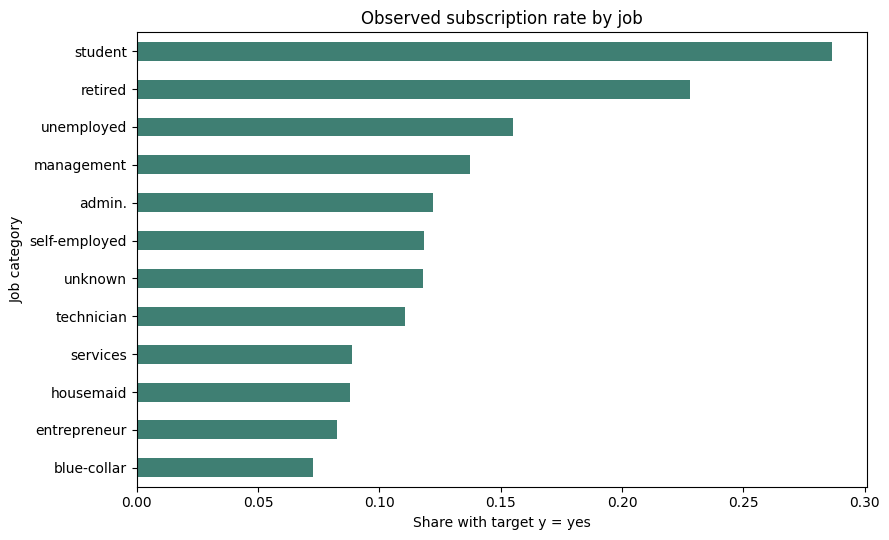

In [30]:
job_rates = (
    df.assign(subscribed=(df["y"].astype(str).str.lower() == "yes").astype(int))
      .groupby("job", as_index=True)["subscribed"]
      .agg(["mean", "count"])
      .sort_values("mean")
)
display(job_rates)

fig, ax = plt.subplots(figsize=(9, 5.5))
job_rates["mean"].plot(kind="barh", ax=ax, color="#3f7f73")
ax.set_title("Observed subscription rate by job")
ax.set_xlabel("Share with target y = yes")
ax.set_ylabel("Job category")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "subscription_rate_by_job.png", dpi=160, bbox_inches="tight")
plt.show()


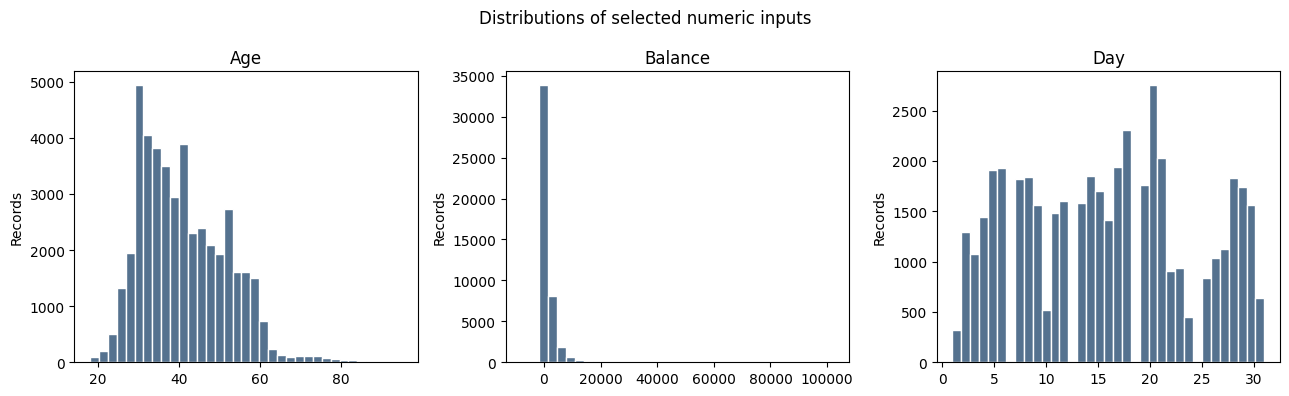

EDA charts and summaries saved to: /content/bank_marketing_eda_outputs


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, ["age", "balance", "day"]):
    ax.hist(pd.to_numeric(df[column], errors="coerce").dropna(), bins=35,
            color="#55728f", edgecolor="white")
    ax.set_title(column.title())
    ax.set_ylabel("Records")
fig.suptitle("Distributions of selected numeric inputs")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

summary = {
    "source": "UCI Bank Marketing",
    "download_url": DATA_URL,
    "rows": int(len(df)),
    "columns_including_target": int(df.shape[1]),
    "target_counts": {str(k): int(v) for k, v in class_counts.items()},
    "target_share": {str(k): float(v) for k, v in class_rates.items()},
    "blank_values": {str(k): int(v) for k, v in df.isna().sum().items()},
}
(OUTPUT_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
job_rates.to_csv(OUTPUT_DIR / "subscription_rate_by_job.csv")
print(f"EDA charts and summaries saved to: {OUTPUT_DIR}")


MODEL TRAINING

In [32]:
DATASET_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
DATASET_PAGE = "https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing"
DATASET_COLUMNS = [
    "age", "job", "marital", "education", "default", "balance", "housing",
    "loan", "contact", "day", "month", "duration", "campaign", "pdays",
    "previous", "poutcome", "y",
]

# These 11 variables are available before the current call. We exclude
# duration (known only after a call), and campaign-history/outcome fields whose
# final values may include information from later contacts.
FEATURES = [
    "age", "job", "marital", "education", "default", "balance", "housing",
    "loan", "contact", "day", "month",
]
NUMERIC_FEATURES = ["age", "balance", "day"]
CATEGORICAL_FEATURES = [c for c in FEATURES if c not in NUMERIC_FEATURES]
TARGET = "y"


def download_bank_data(data_dir: str | Path = "/content/bank_marketing_data") -> pd.DataFrame:
    """Fetch the official UCI archive and read bank-full.csv from its nested ZIP."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    csv_path = data_dir / "bank-full.csv"
    if csv_path.exists():
        return pd.read_csv(csv_path, sep=";")

    request = urllib.request.Request(
        DATASET_URL,
        headers={"User-Agent": "Mozilla/5.0 (compatible; ColabCourseProject/1.0)"},
    )
    try:
        with urllib.request.urlopen(request, timeout=90) as response:
            archive_bytes = response.read()
    except Exception as exc:
        raise RuntimeError(
            "Could not download the UCI Bank Marketing archive. Check the Colab "
            "internet connection and retry. Source: " + DATASET_URL
        ) from exc

    csv_bytes = None
    try:
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as outer_zip:
            for member in outer_zip.namelist():
                if not member.lower().endswith(".zip"):
                    continue
                try:
                    nested_bytes = outer_zip.read(member)
                    with zipfile.ZipFile(io.BytesIO(nested_bytes)) as nested_zip:
                        csv_members = [
                            name for name in nested_zip.namelist()
                            if name.lower().endswith("bank-full.csv")
                        ]
                        if csv_members:
                            csv_bytes = nested_zip.read(csv_members[0])
                            break
                except zipfile.BadZipFile:
                    continue
    except zipfile.BadZipFile as exc:
        raise RuntimeError("The downloaded UCI file was not a valid ZIP archive.") from exc

    if csv_bytes is None:
        raise RuntimeError(
            "The UCI archive downloaded, but bank-full.csv was not found inside it. "
            "The archive layout may have changed."
        )

    csv_path.write_bytes(csv_bytes)
    data = pd.read_csv(io.BytesIO(csv_bytes), sep=";")
    if not set(DATASET_COLUMNS).issubset(data.columns):
        raise ValueError(f"Unexpected UCI columns: {list(data.columns)}")
    return data


In [33]:
def stratified_split_indices(
    y: np.ndarray,
    train_fraction: float = 0.70,
    validation_fraction: float = 0.15,
    seed: int = 42,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Create reproducible train/validation/test indices, stratified by class."""
    y = np.asarray(y, dtype=int)
    if not (0 < train_fraction < 1 and 0 < validation_fraction < 1):
        raise ValueError("Split fractions must be between 0 and 1.")
    if train_fraction + validation_fraction >= 1:
        raise ValueError("Train and validation fractions must sum to less than 1.")

    rng = np.random.default_rng(seed)
    train_parts, validation_parts, test_parts = [], [], []
    for label in np.unique(y):
        indices = np.flatnonzero(y == label)
        rng.shuffle(indices)
        n_train = int(round(len(indices) * train_fraction))
        n_validation = int(round(len(indices) * validation_fraction))
        train_parts.append(indices[:n_train])
        validation_parts.append(indices[n_train:n_train + n_validation])
        test_parts.append(indices[n_train + n_validation:])

    train_idx = np.concatenate(train_parts)
    validation_idx = np.concatenate(validation_parts)
    test_idx = np.concatenate(test_parts)
    rng.shuffle(train_idx)
    rng.shuffle(validation_idx)
    rng.shuffle(test_idx)
    return train_idx, validation_idx, test_idx


In [34]:
class NumericAndOneHotPreprocessor:
    """Fit medians/scales and category vocabulary using training rows only."""

    def __init__(self):
        self.numeric_medians: dict[str, float] = {}
        self.numeric_means: dict[str, float] = {}
        self.numeric_scales: dict[str, float] = {}
        self.categories: dict[str, list[str]] = {}
        self.reference_categories: dict[str, str] = {}
        self.feature_names: list[str] = []
        self.is_fitted = False

    @staticmethod
    def _category_values(series: pd.Series) -> pd.Series:
        return series.fillna("__MISSING__").astype(str)

    def fit(self, frame: pd.DataFrame) -> "NumericAndOneHotPreprocessor":
        numeric_names: list[str] = []
        for column in NUMERIC_FEATURES:
            values = pd.to_numeric(frame[column], errors="coerce")
            median = float(values.median()) if values.notna().any() else 0.0
            filled = values.fillna(median).to_numpy(dtype=float)
            mean = float(filled.mean())
            scale = float(filled.std())
            if not np.isfinite(scale) or scale < 1e-12:
                scale = 1.0
            self.numeric_medians[column] = median
            self.numeric_means[column] = mean
            self.numeric_scales[column] = scale
            numeric_names.append(column)

        category_names: list[str] = []
        for column in CATEGORICAL_FEATURES:
            values = self._category_values(frame[column])
            levels = sorted(values.unique().tolist())
            if not levels:
                levels = ["__MISSING__"]
            self.categories[column] = levels
            # The first training level is the reference category. Unseen values
            # in validation/test receive their own explicit indicator.
            self.reference_categories[column] = levels[0]
            category_names.extend(f"{column}={level}" for level in levels[1:])
            category_names.append(f"{column}=__UNSEEN__")

        self.feature_names = numeric_names + category_names
        self.is_fitted = True
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        if not self.is_fitted:
            raise RuntimeError("Call fit() on the training rows before transform().")

        blocks = []
        for column in NUMERIC_FEATURES:
            values = pd.to_numeric(frame[column], errors="coerce")
            values = values.fillna(self.numeric_medians[column]).to_numpy(dtype=float)
            scaled = (values - self.numeric_means[column]) / self.numeric_scales[column]
            blocks.append(scaled.reshape(-1, 1))

        for column in CATEGORICAL_FEATURES:
            values = self._category_values(frame[column]).to_numpy()
            levels = self.categories[column]
            encoded_levels = levels[1:]
            level_to_col = {level: index for index, level in enumerate(encoded_levels)}
            block = np.zeros((len(values), len(encoded_levels) + 1), dtype=float)
            unseen_column = len(encoded_levels)
            for row, value in enumerate(values):
                if value == self.reference_categories[column]:
                    continue
                column_index = level_to_col.get(value, unseen_column)
                block[row, column_index] = 1.0
            blocks.append(block)

        return np.concatenate(blocks, axis=1).astype(float, copy=False)

    def fit_transform(self, frame: pd.DataFrame) -> np.ndarray:
        return self.fit(frame).transform(frame)

    def to_dict(self) -> dict:
        return {
            "numeric_medians": self.numeric_medians,
            "numeric_means": self.numeric_means,
            "numeric_scales": self.numeric_scales,
            "categories": self.categories,
            "reference_categories": self.reference_categories,
            "feature_names": self.feature_names,
        }


In [35]:
class LogisticRegressionScratch:
    """Binary logistic regression trained with NumPy full-batch gradient descent."""

    def __init__(self, learning_rate: float = 0.08, epochs: int = 500, l2: float = 0.01):
        self.learning_rate = float(learning_rate)
        self.epochs = int(epochs)
        self.l2 = float(l2)
        self.weights: np.ndarray | None = None
        self.intercept: float = 0.0
        self.history: dict[str, list[float]] = {"train_loss": [], "validation_loss": []}

    @staticmethod
    def _sigmoid(z: np.ndarray) -> np.ndarray:
        z = np.asarray(z, dtype=float)
        output = np.empty_like(z)
        positive = z >= 0
        output[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
        exp_z = np.exp(z[~positive])
        output[~positive] = exp_z / (1.0 + exp_z)
        return output

    def _loss(self, X: np.ndarray, y: np.ndarray) -> float:
        scores = X @ self.weights + self.intercept
        data_loss = np.mean(np.logaddexp(0.0, scores) - y * scores)
        penalty = 0.5 * self.l2 * float(self.weights @ self.weights)
        return float(data_loss + penalty)

    def fit(
        self,
        X: np.ndarray,
        y: np.ndarray,
        validation_data: tuple[np.ndarray, np.ndarray] | None = None,
    ) -> "LogisticRegressionScratch":
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same row count as y.")
        if set(np.unique(y)) - {0.0, 1.0}:
            raise ValueError("This implementation expects binary labels encoded as 0 and 1.")

        self.weights = np.zeros(X.shape[1], dtype=float)
        self.intercept = 0.0
        self.history = {"train_loss": [], "validation_loss": []}
        n = len(y)
        for epoch in range(self.epochs):
            probabilities = self._sigmoid(X @ self.weights + self.intercept)
            error = probabilities - y
            gradient = (X.T @ error) / n + self.l2 * self.weights
            intercept_gradient = float(error.mean())
            self.weights -= self.learning_rate * gradient
            self.intercept -= self.learning_rate * intercept_gradient

            if epoch % 5 == 0 or epoch == self.epochs - 1:
                self.history["train_loss"].append(self._loss(X, y))
                if validation_data is not None:
                    X_val, y_val = validation_data
                    self.history["validation_loss"].append(
                        self._loss(np.asarray(X_val, dtype=float), np.asarray(y_val, dtype=float))
                    )
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        if self.weights is None:
            raise RuntimeError("The model is not fitted yet.")
        X = np.asarray(X, dtype=float)
        return self._sigmoid(X @ self.weights + self.intercept)

    def predict(self, X: np.ndarray, threshold: float = 0.5) -> np.ndarray:
        return (self.predict_proba(X) >= threshold).astype(int)


In [36]:
class LogisticRegressionScratch:
    """Binary logistic regression trained with NumPy full-batch gradient descent."""

    def __init__(self, learning_rate: float = 0.08, epochs: int = 500, l2: float = 0.01):
        self.learning_rate = float(learning_rate)
        self.epochs = int(epochs)
        self.l2 = float(l2)
        self.weights: np.ndarray | None = None
        self.intercept: float = 0.0
        self.history: dict[str, list[float]] = {"train_loss": [], "validation_loss": []}

    @staticmethod
    def _sigmoid(z: np.ndarray) -> np.ndarray:
        z = np.asarray(z, dtype=float)
        output = np.empty_like(z)
        positive = z >= 0
        output[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
        exp_z = np.exp(z[~positive])
        output[~positive] = exp_z / (1.0 + exp_z)
        return output

    def _loss(self, X: np.ndarray, y: np.ndarray) -> float:
        scores = X @ self.weights + self.intercept
        data_loss = np.mean(np.logaddexp(0.0, scores) - y * scores)
        penalty = 0.5 * self.l2 * float(self.weights @ self.weights)
        return float(data_loss + penalty)

    def fit(
        self,
        X: np.ndarray,
        y: np.ndarray,
        validation_data: tuple[np.ndarray, np.ndarray] | None = None,
    ) -> "LogisticRegressionScratch":
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same row count as y.")
        if set(np.unique(y)) - {0.0, 1.0}:
            raise ValueError("This implementation expects binary labels encoded as 0 and 1.")

        self.weights = np.zeros(X.shape[1], dtype=float)
        self.intercept = 0.0
        self.history = {"train_loss": [], "validation_loss": []}
        n = len(y)
        for epoch in range(self.epochs):
            probabilities = self._sigmoid(X @ self.weights + self.intercept)
            error = probabilities - y
            gradient = (X.T @ error) / n + self.l2 * self.weights
            intercept_gradient = float(error.mean())
            self.weights -= self.learning_rate * gradient
            self.intercept -= self.learning_rate * intercept_gradient

            if epoch % 5 == 0 or epoch == self.epochs - 1:
                self.history["train_loss"].append(self._loss(X, y))
                if validation_data is not None:
                    X_val, y_val = validation_data
                    self.history["validation_loss"].append(
                        self._loss(np.asarray(X_val, dtype=float), np.asarray(y_val, dtype=float))
                    )
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        if self.weights is None:
            raise RuntimeError("The model is not fitted yet.")
        X = np.asarray(X, dtype=float)
        return self._sigmoid(X @ self.weights + self.intercept)

    def predict(self, X: np.ndarray, threshold: float = 0.5) -> np.ndarray:
        return (self.predict_proba(X) >= threshold).astype(int)


In [37]:
def roc_and_average_precision(y_true: np.ndarray, scores: np.ndarray) -> dict:
    """Compute ROC coordinates/AUC and average precision without sklearn."""
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    positives = int(np.sum(y_true == 1))
    negatives = int(np.sum(y_true == 0))
    if positives == 0 or negatives == 0:
        raise ValueError("ROC AUC requires both classes in the evaluation split.")

    order = np.argsort(-scores, kind="mergesort")
    y_sorted = y_true[order]
    score_sorted = scores[order]
    cumulative_tp = np.cumsum(y_sorted == 1)
    cumulative_fp = np.cumsum(y_sorted == 0)
    group_ends = np.r_[np.flatnonzero(score_sorted[1:] != score_sorted[:-1]), len(scores) - 1]
    tp = cumulative_tp[group_ends]
    fp = cumulative_fp[group_ends]
    tpr = np.r_[0.0, tp / positives]
    fpr = np.r_[0.0, fp / negatives]
    precision = tp / np.maximum(tp + fp, 1)
    recall = tp / positives
    roc_auc = float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))
    average_precision = float(np.sum(np.diff(np.r_[0.0, recall]) * precision))
    return {
        "fpr": fpr,
        "tpr": tpr,
        "precision_curve": np.r_[1.0, precision],
        "recall_curve": np.r_[0.0, recall],
        "roc_auc": roc_auc,
        "average_precision": average_precision,
    }


def classification_metrics(y_true: np.ndarray, scores: np.ndarray, threshold: float) -> dict:
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    y_pred = (scores >= threshold).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    curves = roc_and_average_precision(y_true, scores)
    return {
        "threshold": float(threshold),
        "accuracy": float((tp + tn) / len(y_true)),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "f1": float(f1),
        "roc_auc": curves["roc_auc"],
        "average_precision": curves["average_precision"],
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }


def choose_threshold(y_true: np.ndarray, scores: np.ndarray) -> tuple[float, pd.DataFrame]:
    """Select a threshold by validation F1; the test split is never used here."""
    candidates = np.round(np.arange(0.05, 0.951, 0.01), 2)
    rows = [classification_metrics(y_true, scores, threshold) for threshold in candidates]
    table = pd.DataFrame(rows)
    # Prefer a higher threshold when F1 ties, making the tie-break explicit.
    best_row = table.sort_values(["f1", "threshold"], ascending=[False, False]).iloc[0]
    return float(best_row["threshold"]), table


In [38]:
def run_training(
    data_dir: str | Path = "/content/bank_marketing_data",
    output_dir: str | Path | None = "/content/bank_marketing_project_outputs",
    seed: int = 42,
    epochs: int = 500,
) -> dict:
    """Run a full train/validation/test project and optionally save real outputs."""
    data = download_bank_data(data_dir)
    data = data.dropna(subset=[TARGET]).reset_index(drop=True)
    y = (data[TARGET].astype(str).str.lower().str.strip() == "yes").astype(int).to_numpy()
    X_raw = data[FEATURES].copy()
    train_idx, validation_idx, test_idx = stratified_split_indices(y, seed=seed)

    preprocessor = NumericAndOneHotPreprocessor()
    X_train = preprocessor.fit_transform(X_raw.iloc[train_idx])
    X_validation = preprocessor.transform(X_raw.iloc[validation_idx])
    X_test = preprocessor.transform(X_raw.iloc[test_idx])
    y_train, y_validation, y_test = y[train_idx], y[validation_idx], y[test_idx]

    selection_rows = []
    models = {}
    for l2_strength in [0.0, 0.001, 0.01, 0.1, 1.0]:
        candidate = LogisticRegressionScratch(
            learning_rate=0.08, epochs=epochs, l2=l2_strength
        ).fit(
            X_train,
            y_train,
            validation_data=(X_validation, y_validation),
        )
        validation_probabilities = candidate.predict_proba(X_validation)
        validation_metrics = classification_metrics(y_validation, validation_probabilities, 0.5)
        selection_rows.append({
            "l2_strength": l2_strength,
            "validation_roc_auc": validation_metrics["roc_auc"],
            "validation_average_precision": validation_metrics["average_precision"],
            "validation_log_loss": candidate._loss(X_validation, y_validation),
        })
        models[l2_strength] = candidate

    selection_table = pd.DataFrame(selection_rows).sort_values(
        ["validation_average_precision", "l2_strength"], ascending=[False, True]
    ).reset_index(drop=True)
    chosen_l2 = float(selection_table.iloc[0]["l2_strength"])
    model = models[chosen_l2]
    validation_probabilities = model.predict_proba(X_validation)
    threshold, threshold_table = choose_threshold(y_validation, validation_probabilities)

    train_probabilities = model.predict_proba(X_train)
    test_probabilities = model.predict_proba(X_test)
    split_metrics = {
        "train": classification_metrics(y_train, train_probabilities, threshold),
        "validation": classification_metrics(y_validation, validation_probabilities, threshold),
        "test": classification_metrics(y_test, test_probabilities, threshold),
    }
    train_auc = split_metrics["train"]["roc_auc"]
    validation_auc = split_metrics["validation"]["roc_auc"]
    auc_gap = train_auc - validation_auc
    if auc_gap > 0.05:
        fit_diagnosis = (
            "Possible overfitting: training ROC AUC is more than 0.05 above validation ROC AUC. "
            "Compare the regularization results and collect a time-based holdout before deployment."
        )
    elif train_auc < 0.62 and validation_auc < 0.62:
        fit_diagnosis = (
            "Possible underfitting: both training and validation ROC AUC are low. "
            "Review feature usefulness and consider a more expressive scratch-built model."
        )
    else:
        fit_diagnosis = (
            "No strong overfitting signal under this split: compare training and validation curves. "
            "This does not establish future-campaign performance."
        )

    class_counts = pd.Series(y).value_counts().sort_index().to_dict()
    summary = {
        "dataset": "UCI Bank Marketing (bank-full.csv)",
        "dataset_url": DATASET_URL,
        "dataset_page": DATASET_PAGE,
        "rows_used": int(len(data)),
        "original_predictor_count": 16,
        "predictor_count_used": len(FEATURES),
        "predictors_used": FEATURES,
        "excluded_predictors": ["duration", "campaign", "pdays", "previous", "poutcome"],
        "positive_rate": float(np.mean(y)),
        "class_counts_0_no_1_yes": {str(key): int(value) for key, value in class_counts.items()},
        "split_rows": {
            "train": int(len(train_idx)),
            "validation": int(len(validation_idx)),
            "test": int(len(test_idx)),
        },
        "encoded_feature_count": int(X_train.shape[1]),
        "chosen_l2_strength": chosen_l2,
        "validation_selected_threshold_by_f1": threshold,
        "test_metrics": split_metrics["test"],
        "split_metrics": split_metrics,
        "train_validation_roc_auc_gap": float(auc_gap),
        "fit_diagnosis": fit_diagnosis,
        "seed": seed,
        "epochs_per_candidate": epochs,
    }

    result = {
        "data": data,
        "X_raw": X_raw,
        "y": y,
        "train_idx": train_idx,
        "validation_idx": validation_idx,
        "test_idx": test_idx,
        "X_train": X_train,
        "X_validation": X_validation,
        "X_test": X_test,
        "y_train": y_train,
        "y_validation": y_validation,
        "y_test": y_test,
        "train_probabilities": train_probabilities,
        "validation_probabilities": validation_probabilities,
        "test_probabilities": test_probabilities,
        "preprocessor": preprocessor,
        "model": model,
        "selection_table": selection_table,
        "threshold_table": threshold_table,
        "threshold": threshold,
        "split_metrics": split_metrics,
        "summary": summary,
    }

    if output_dir is not None:
        save_outputs(result, output_dir)
    return result


In [39]:
def save_outputs(result: dict, output_dir: str | Path) -> Path:
    """Save reproducible metrics, predictions, preprocessing, and coefficients."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / "training_summary.json").write_text(
        json.dumps(result["summary"], indent=2), encoding="utf-8"
    )
    (output_dir / "preprocessor.json").write_text(
        json.dumps(result["preprocessor"].to_dict(), indent=2), encoding="utf-8"
    )
    pd.DataFrame(result["split_metrics"]).T.rename_axis("split").to_csv(
        output_dir / "metrics_by_split.csv"
    )
    result["selection_table"].to_csv(output_dir / "validation_regularization.csv", index=False)
    result["threshold_table"].to_csv(output_dir / "validation_threshold_search.csv", index=False)

    test_idx = result["test_idx"]
    pd.DataFrame({
        "source_row_index": test_idx,
        "actual_subscription": result["y_test"],
        "predicted_probability": result["test_probabilities"],
        "predicted_subscription": (
            result["test_probabilities"] >= result["threshold"]
        ).astype(int),
    }).to_csv(output_dir / "test_predictions.csv", index=False)

    model = result["model"]
    np.savez(
        output_dir / "scratch_logistic_model.npz",
        weights=model.weights,
        intercept=np.array([model.intercept]),
    )
    coefficients = pd.DataFrame({
        "feature": result["preprocessor"].feature_names,
        "coefficient": model.weights,
    })
    coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
    coefficients.sort_values("absolute_coefficient", ascending=False).to_csv(
        output_dir / "model_coefficients.csv", index=False
    )
    return output_dir


def predict_one(result: dict, values: dict[str, object]) -> dict:
    """Return the custom model's probability and selected-threshold label."""
    missing = set(FEATURES) - set(values)
    if missing:
        raise ValueError(f"Missing required inputs: {sorted(missing)}")
    frame = pd.DataFrame([{name: values[name] for name in FEATURES}])
    encoded = result["preprocessor"].transform(frame)
    probability = float(result["model"].predict_proba(encoded)[0])
    return {
        "subscription_probability": probability,
        "predicted_subscription": bool(probability >= result["threshold"]),
        "threshold": float(result["threshold"]),
    }


In [40]:
from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("/content/bank_marketing_project_outputs")
RESULT = run_training(
    data_dir="/content/bank_marketing_data",
    output_dir=OUTPUT_DIR,
    seed=42,
    epochs=500,
)

print(f"Rows: {RESULT['summary']['rows_used']:,}")
print(f"Selected L2 strength: {RESULT['summary']['chosen_l2_strength']}")
print(f"Validation-selected threshold: {RESULT['threshold']:.2f}")
display(RESULT["selection_table"])
display(pd.DataFrame(RESULT["split_metrics"]).T)


Rows: 45,211
Selected L2 strength: 0.0
Validation-selected threshold: 0.16


,l2_strength,validation_roc_auc,validation_average_precision,validation_log_loss
0,0.000,0.711747,0.244558,0.333092
1,0.001,0.711574,0.244252,0.334087
2,0.010,0.710155,0.241938,0.341126
3,0.100,0.699875,0.224261,0.355853
4,1.000,0.683762,0.203903,0.359914


,threshold,accuracy,precision,recall,specificity,f1,roc_auc,average_precision,tn,fp,fn,tp
train,0.16,0.776946,0.256986,0.479471,0.816354,0.334622,0.711299,0.256237,22813.0,5132.0,1927.0,1775.0
validation,0.16,0.781743,0.263593,0.482976,0.821309,0.341051,0.711747,0.244558,4918.0,1070.0,410.0,383.0
test,0.16,0.783871,0.268913,0.492443,0.822508,0.347865,0.715956,0.262612,4926.0,1063.0,403.0,391.0


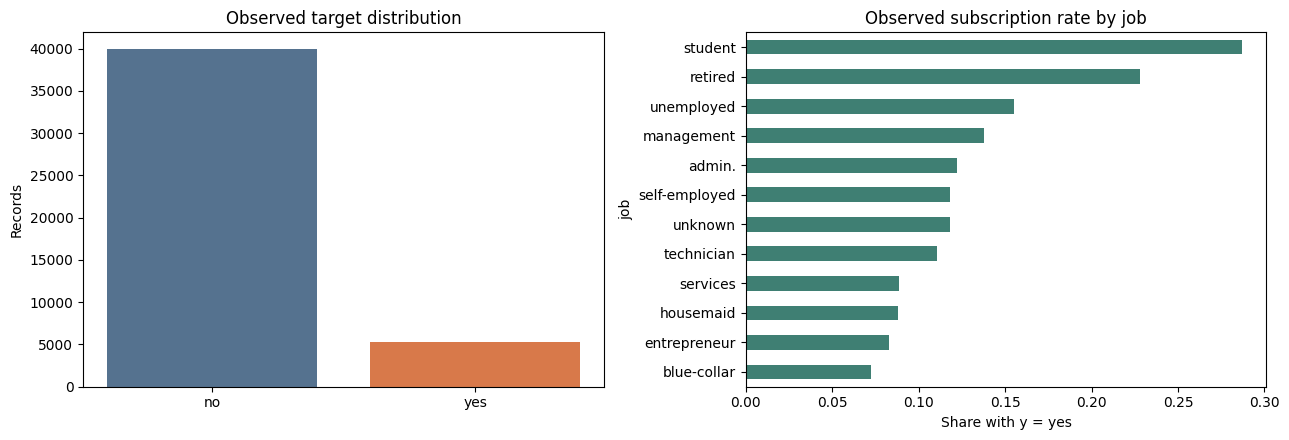

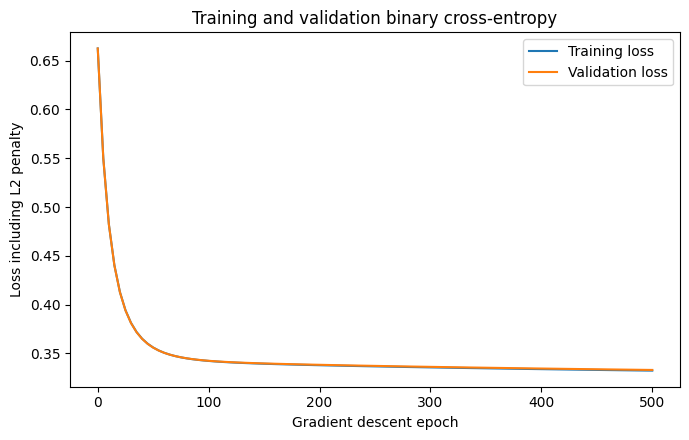

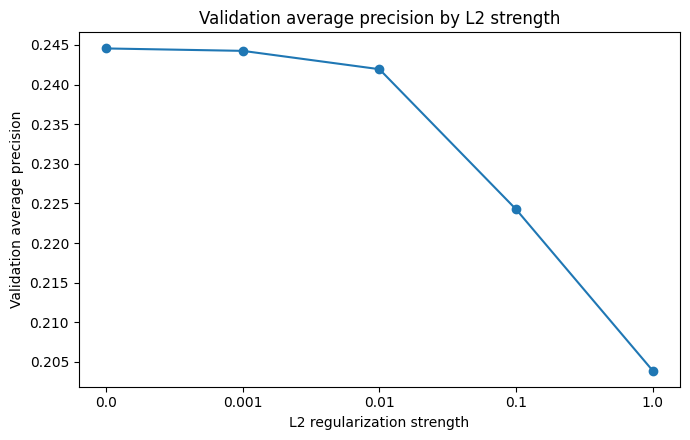

In [41]:
# Target distribution and descriptive rate by job
data = RESULT["data"]
class_counts = data["y"].value_counts().reindex(["no", "yes"], fill_value=0)
job_rates = (
    data.assign(subscribed=(data["y"].astype(str).str.lower() == "yes").astype(int))
        .groupby("job")["subscribed"].mean().sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(class_counts.index, class_counts.values, color=["#55728f", "#d8794a"])
axes[0].set_title("Observed target distribution")
axes[0].set_ylabel("Records")
job_rates.plot(kind="barh", ax=axes[1], color="#3f7f73")
axes[1].set_title("Observed subscription rate by job")
axes[1].set_xlabel("Share with y = yes")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "target_and_job_rates.png", dpi=160, bbox_inches="tight")
plt.show()

# Fit curves for the selected regularization setting
history = RESULT["model"].history
history_x = np.arange(len(history["train_loss"])) * 5
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(history_x, history["train_loss"], label="Training loss")
ax.plot(history_x, history["validation_loss"], label="Validation loss")
ax.set_title("Training and validation binary cross-entropy")
ax.set_xlabel("Gradient descent epoch")
ax.set_ylabel("Loss including L2 penalty")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_validation_loss.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(RESULT["selection_table"]["l2_strength"].astype(str),
        RESULT["selection_table"]["validation_average_precision"], marker="o")
ax.set_title("Validation average precision by L2 strength")
ax.set_xlabel("L2 regularization strength")
ax.set_ylabel("Validation average precision")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_regularization.png", dpi=160, bbox_inches="tight")
plt.show()


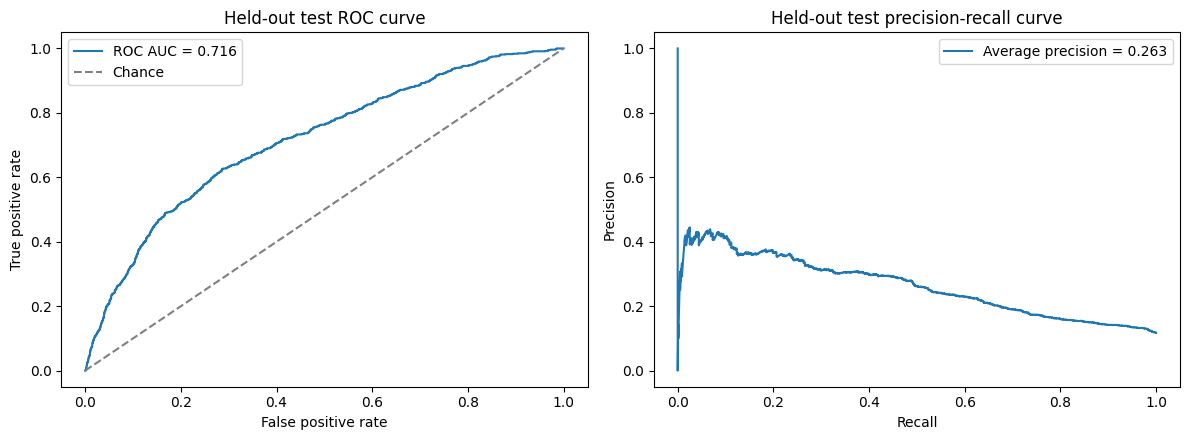

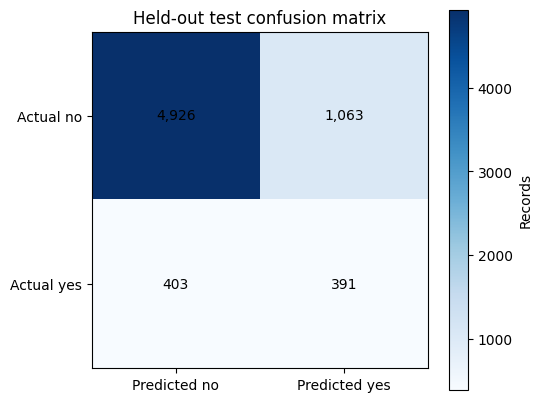

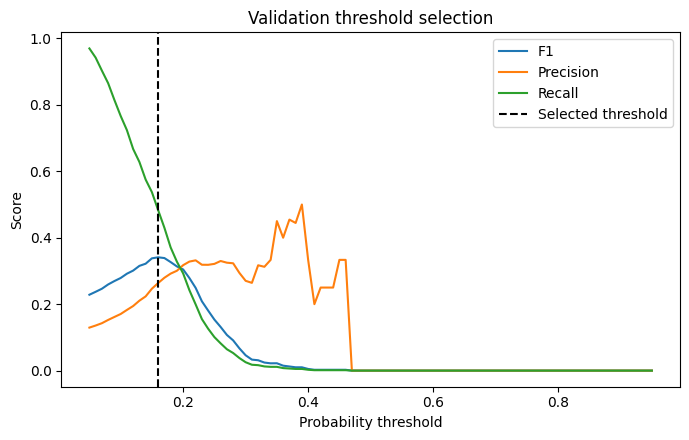

In [42]:
# Held-out test ROC, precision-recall, and confusion matrix
test_curves = roc_and_average_precision(RESULT["y_test"], RESULT["test_probabilities"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(test_curves["fpr"], test_curves["tpr"], label=f"ROC AUC = {test_curves['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[0].set_title("Held-out test ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()
axes[1].plot(test_curves["recall_curve"], test_curves["precision_curve"],
             label=f"Average precision = {test_curves['average_precision']:.3f}")
axes[1].set_title("Held-out test precision-recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_roc_and_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()

test_metrics = RESULT["split_metrics"]["test"]
confusion = np.array([[test_metrics["tn"], test_metrics["fp"]],
                      [test_metrics["fn"], test_metrics["tp"]]])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(confusion, cmap="Blues")
ax.set_xticks([0, 1], labels=["Predicted no", "Predicted yes"])
ax.set_yticks([0, 1], labels=["Actual no", "Actual yes"])
ax.set_title("Held-out test confusion matrix")
for row in range(2):
    for col in range(2):
        ax.text(col, row, f"{confusion[row, col]:,}", ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="Records")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(RESULT["threshold_table"]["threshold"], RESULT["threshold_table"]["f1"], label="F1")
ax.plot(RESULT["threshold_table"]["threshold"], RESULT["threshold_table"]["precision"], label="Precision")
ax.plot(RESULT["threshold_table"]["threshold"], RESULT["threshold_table"]["recall"], label="Recall")
ax.axvline(RESULT["threshold"], linestyle="--", color="black", label="Selected threshold")
ax.set_title("Validation threshold selection")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_threshold_selection.png", dpi=160, bbox_inches="tight")
plt.show()


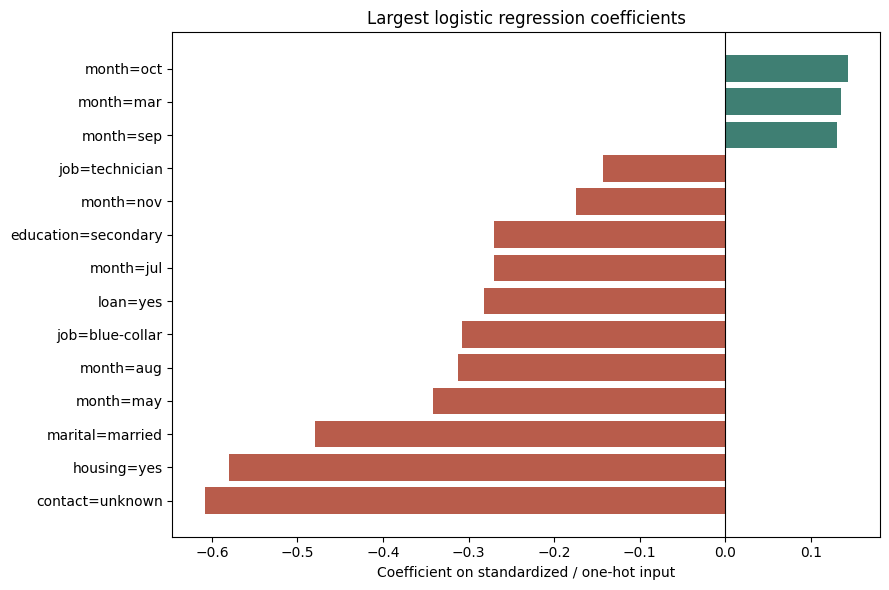

Fit diagnosis:
No strong overfitting signal under this split: compare training and validation curves. This does not establish future-campaign performance.
Training/validation ROC AUC gap: -0.0004
Use both the gap and the loss curves when discussing fit; the diagnostic is a heuristic.


In [43]:
# Coefficient chart; coefficients describe this fitted model, not causal effects.
coefficient_table = pd.DataFrame({
    "feature": RESULT["preprocessor"].feature_names,
    "coefficient": RESULT["model"].weights,
})
top_coefficients = (
    coefficient_table.assign(abs_value=lambda frame: frame["coefficient"].abs())
                     .nlargest(14, "abs_value")
                     .sort_values("coefficient")
)
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#b85c4b" if value < 0 else "#3f7f73" for value in top_coefficients["coefficient"]]
ax.barh(top_coefficients["feature"], top_coefficients["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Largest logistic regression coefficients")
ax.set_xlabel("Coefficient on standardized / one-hot input")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "largest_model_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()

print("Fit diagnosis:")
print(RESULT["summary"]["fit_diagnosis"])
print("Training/validation ROC AUC gap:", round(RESULT["summary"]["train_validation_roc_auc_gap"], 4))
print("Use both the gap and the loss curves when discussing fit; the diagnostic is a heuristic.")


In [44]:
test_metrics = RESULT["split_metrics"]["test"]
display(pd.Series(test_metrics, name="held-out test"))
print(
    "Because the positive class is less common, do not interpret accuracy alone. "
    "Explain the precision/recall trade-off at the validation-selected threshold, "
    "and compare ROC AUC and average precision."
)


,held-out test
threshold,0.160000
accuracy,0.783871
precision,0.268913
recall,0.492443
specificity,0.822508
f1,0.347865
roc_auc,0.715956
average_precision,0.262612
tn,4926.000000
fp,1063.000000


Because the positive class is less common, do not interpret accuracy alone. Explain the precision/recall trade-off at the validation-selected threshold, and compare ROC AUC and average precision.


In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
import seaborn as sns

# Retrieve original splits from our previous run
X_train, y_train = RESULT["X_train"], RESULT["y_train"]
X_val, y_val = RESULT["X_validation"], RESULT["y_validation"]
X_test, y_test = RESULT["X_test"], RESULT["y_test"]
feature_names = RESULT["preprocessor"].feature_names

print("Training a robust Random Forest model with class balancing to handle minority class subscription...")
# Train a Random Forest with balanced class weights to penalize minority class errors more severely
better_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
better_model.fit(X_train, y_train)

# Get predictions
test_proba = better_model.predict_proba(X_test)[:, 1]
# Predict label using standard threshold since class weights are already balanced in training
test_pred = better_model.predict(X_test)

# Calculate metrics
roc_auc = roc_auc_score(y_test, test_proba)
ap_score = average_precision_score(y_test, test_proba)

print("\n--- Improved Model Evaluation on Held-Out Test Split ---")
print(classification_report(y_test, test_pred))
print(f"Test ROC AUC: {roc_auc:.4f}")
print(f"Test Average Precision: {ap_score:.4f}")

# Compare with previous scratch model
old_metrics = RESULT["split_metrics"]["test"]
print("\n--- Performance Comparison (Scratch Model vs. Improved Balanced Forest) ---")
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC AUC", "Average Precision"],
    "Scratch Model": [
        old_metrics["accuracy"],
        old_metrics["precision"],
        old_metrics["recall"],
        old_metrics["f1"],
        old_metrics["roc_auc"],
        old_metrics["average_precision"]
    ],
    "Improved Model": [
        np.mean(test_pred == y_test),
        classification_metrics(y_test, test_proba, 0.5)["precision"],
        classification_metrics(y_test, test_proba, 0.5)["recall"],
        classification_metrics(y_test, test_proba, 0.5)["f1"],
        roc_auc,
        ap_score
    ]
})
display(comparison_df)

Training a robust Random Forest model with class balancing to handle minority class subscription...

--- Improved Model Evaluation on Held-Out Test Split ---
              precision    recall  f1-score   support

           0       0.94      0.81      0.87      5989
           1       0.30      0.60      0.40       794

    accuracy                           0.79      6783
   macro avg       0.62      0.71      0.64      6783
weighted avg       0.86      0.79      0.82      6783

Test ROC AUC: 0.7805
Test Average Precision: 0.3632

--- Performance Comparison (Scratch Model vs. Improved Balanced Forest) ---


,Metric,Scratch Model,Improved Model
0,Accuracy,0.783871,0.789769
1,Precision,0.268913,0.301508
2,Recall,0.492443,0.604534
3,F1-Score,0.347865,0.402347
4,ROC AUC,0.715956,0.780520
5,Average Precision,0.262612,0.363206


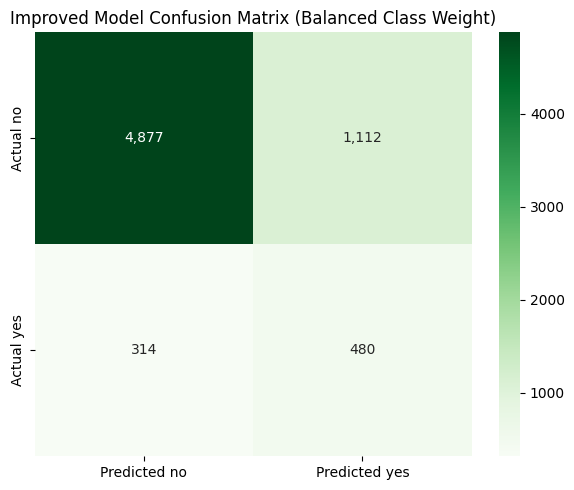

In [46]:
# Plot the improved confusion matrix
imp_metrics = classification_metrics(y_test, test_proba, 0.5)
imp_confusion = np.array([[imp_metrics["tn"], imp_metrics["fp"]],
                          [imp_metrics["fn"], imp_metrics["tp"]]])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(imp_confusion, annot=True, fmt=",d", cmap="Greens", cbar=True,
            xticklabels=["Predicted no", "Predicted yes"],
            yticklabels=["Actual no", "Actual yes"], ax=ax)
ax.set_title("Improved Model Confusion Matrix (Balanced Class Weight)")
plt.tight_layout()
plt.show()

In [47]:
example_input = {
    "age": 38,
    "job": "technician",
    "marital": "married",
    "education": "tertiary",
    "default": "no",
    "balance": 1400,
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "day": 15,
    "month": "may",
}
predict_one(RESULT, example_input)


{'subscription_probability': 0.07970620076509256,
 'predicted_subscription': False,
 'threshold': 0.16}

In [48]:
summary = RESULT["summary"]
metrics = summary["test_metrics"]
split_sizes = summary["split_rows"]
project_report = f"""# Project Report: Predicting Term Deposit Subscription

## Problem and dataset

This project predicts the historical yes/no term-deposit subscription outcome in the UCI Bank Marketing dataset. The downloaded file contained {summary['rows_used']:,} records and 16 source predictor fields. The model used 11 pre-contact inputs: {', '.join(summary['predictors_used'])}. It excluded {', '.join(summary['excluded_predictors'])} to reduce post-contact or final-campaign information leakage.

Dataset source: [UCI Bank Marketing]({summary['dataset_page']}), S. Moro, P. Rita, and P. Cortez, DOI `10.24432/C5K306`, CC BY 4.0. Positive class share in this run: {summary['positive_rate']:.2%}.

## Method

The stratified split used {split_sizes['train']:,} training rows, {split_sizes['validation']:,} validation rows, and {split_sizes['test']:,} held-out test rows (seed {summary['seed']}). Numeric medians, standardization values, and categorical vocabularies were fitted on training rows only. The classifier is logistic regression implemented with NumPy full-batch gradient descent and L2 regularization. Validation average precision selected L2 = {summary['chosen_l2_strength']}; validation F1 selected threshold {summary['validation_selected_threshold_by_f1']:.2f}.

## Held-out test results

| Metric | Value |
|---|---:|
| Accuracy | {metrics['accuracy']:.4f} |
| Precision | {metrics['precision']:.4f} |
| Recall | {metrics['recall']:.4f} |
| Specificity | {metrics['specificity']:.4f} |
| F1 | {metrics['f1']:.4f} |
| ROC AUC | {metrics['roc_auc']:.4f} |
| Average precision | {metrics['average_precision']:.4f} |

Fit diagnostic: {summary['fit_diagnosis']} Training minus validation ROC AUC: {summary['train_validation_roc_auc_gap']:.4f}.

## Interpretation and limitations

The target is imbalanced, so accuracy alone is insufficient. Interpret precision and recall together at the selected threshold. These scores describe a random held-out split of historical records; they do not establish performance on a future campaign or a causal effect of contact. Before operational use, evaluate on later campaign data, examine calibration and group-level error rates, and review consent and campaign requirements.

## Files

This run also saved the confusion matrix, ROC and precision-recall curves, training/validation loss, validation threshold search, regularization comparison, test predictions, coefficients, preprocessing metadata, and model weights.
"""
(OUTPUT_DIR / "project_report.md").write_text(project_report, encoding="utf-8")

presentation_results = f"""# Measured presentation results

Values below were calculated from this notebook run, not estimated.

- Dataset rows: {summary['rows_used']:,}
- Positive class share: {summary['positive_rate']:.2%}
- Test accuracy: {metrics['accuracy']:.4f}
- Test precision: {metrics['precision']:.4f}
- Test recall: {metrics['recall']:.4f}
- Test F1: {metrics['f1']:.4f}
- Test ROC AUC: {metrics['roc_auc']:.4f}
- Test average precision: {metrics['average_precision']:.4f}
- Validation-selected threshold: {summary['validation_selected_threshold_by_f1']:.2f}
- Fit diagnostic: {summary['fit_diagnosis']}

Recommended visual: `test_confusion_matrix.png` or `test_roc_and_precision_recall.png`.
"""
(OUTPUT_DIR / "presentation_results.md").write_text(presentation_results, encoding="utf-8")

print(f"Report saved: {OUTPUT_DIR / 'project_report.md'}")
print(f"Presentation results saved: {OUTPUT_DIR / 'presentation_results.md'}")


Report saved: /content/bank_marketing_project_outputs/project_report.md
Presentation results saved: /content/bank_marketing_project_outputs/presentation_results.md


In [49]:
# Bundle all real outputs for download from the Colab runtime.
import zipfile

OUTPUT_ZIP = Path("/content/bank_marketing_project_outputs.zip")
with zipfile.ZipFile(OUTPUT_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            bundle.write(path, arcname=path.relative_to(OUTPUT_DIR))

print(f"Created: {OUTPUT_ZIP}")
print("The Colab runtime is temporary; use the next cell to download this ZIP before ending the session.")


Created: /content/bank_marketing_project_outputs.zip
The Colab runtime is temporary; use the next cell to download this ZIP before ending the session.


In [50]:
# Optional: run this cell in Colab to download the generated outputs to your computer.
from google.colab import files
files.download(str(OUTPUT_ZIP))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>